<h1><center>Big Data Algorithms Techniques & Platforms</center></h1>
<h2>
<hr style=" border:none; height:3px;">
<center>Spark and MapReduce</center>
<hr style=" border:none; height:3px;">
</h2>

# Rules and Environment set-up

<p align="justify">
<font size="3">
The assigment includes 22 questions on PySpark RDD MapReduce. For this assignment use **ONLY** PySpark RDD transformations (`.map()`, `.filter()`, `.reduceByKey()`, `.aggregateByKey()`, `.flatMap()`, etc.).

**DO NOT** use PySpark DataFrames, Datasets, or Spark SQL.

</font>
</p>





The Base Adresse Nationale (BAN) is the single official database containing every localized postal address across France. Managed jointly by French public authorities—including the IGN (National Institute of Geographic and Forest Information), La Poste, and local municipalities (communes)—it provides authoritative geospatial reference data for public services, emergency response teams, navigation systems, and private logistics.

The dataset contains millions of address points spanning mainland France and overseas territories. Each record represents an individual address point and links textual address metadata to exact geographic coordinates:


*   Administrative Boundaries: Standardized local codes, including 5-digit postal codes (code_postal), 5-character official INSEE municipality identifiers (code_insee), municipality names (nom_commune), and department codes (code_departement).

*   National Identifiers: Unique address identifiers (id) and FANTOIR street directory codes (id_fantoir) used for official record keeping.

*   Geographic Coordinates: Precise WGS 84 latitude and longitude coordinates mapping the location of each address.
*   Address Structure: Detailed building numbers (numero), repetition suffixes (rep such as bis or ter), and official street names (nom_voie or lieu-dit).



In [1]:
%pip install pyspark

Note: you may need to restart the kernel to use updated packages.


In [2]:
# ==========================================
# SETUP & DATA CLEANING
# ==========================================
import csv
import math
from pyspark import SparkConf, SparkContext

conf = SparkConf().setAppName("BAN_MapReduce_22_Exercises")
sc = SparkContext.getOrCreate(conf=conf)

#Example - how to load one partition of the dataset
raw_rdd = sc.textFile("adresses-france.csv.gz")
header = raw_rdd.first()

def parse_line(line):
    return list(next(csv.reader([line], delimiter=';')))

# Clean RDD: Filter out header and invalid column lengths
adresses_rdd = (
    raw_rdd.filter(lambda line: line != header)
    .map(parse_line)
    .filter(lambda cols: len(cols) >= 11)
)

adresses_rdd.cache()
print(f"Loaded & cached {adresses_rdd.count():,} address records.")


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/Users/apple/anaconda3/lib/python3.11/site-packages/pandas/core/arrays/masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
26/10/25 15:38:47 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/25 15:39:10 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 15:39:10 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 15:39:10 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


Loaded & cached 26,121,849 address records.


---
## Exercise 1: Count Addresses per Department
**Goal:** Compute address counts per department (`code_departement`). Output top 10.

**Allowed RDD Functions:** `.map()`, `.reduceByKey()`, `.sortBy()`

In [3]:
raw_rdd.first()

'id;id_fantoir;numero;rep;nom_voie;code_postal;code_insee;nom_commune;code_insee_ancienne_commune;nom_ancienne_commune;x;y;lon;lat;type_position;alias;nom_ld;libelle_acheminement;nom_afnor;source_position;source_nom_voie;certification_commune;cad_parcelles'

**There's no code department in downloaded file so I use the code_postal**

In [4]:
adresses_rdd.take(1)

26/10/25 15:41:26 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 15:41:26 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 15:41:26 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory
Traceback (most recent call last):
  File "/Users/apple/anaconda3/lib/python3.11/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 262, in manager
  File "/Users/apple/anaconda3/lib/python3.11/site-packages/pyspark/python/lib/pyspark.zip/pyspark/daemon.py", line 95, in worker
BrokenPipeError: [Errno 32] Broken pipe


[['01002_0240_00030',
  '01002_0240',
  '30',
  '',
  'Chemin de la Source',
  '01640',
  '01002',
  "L'Abergement-de-Varey",
  '',
  '',
  '887525.42',
  '6548453.08',
  '5.423847',
  '46.009913',
  'entrée',
  '',
  '',
  'L ABERGEMENT DE VAREY',
  'CHEMIN DE LA SOURCE',
  'commune',
  'commune',
  '1',
  '01002000AD0080']]

In [5]:
print("Exercise 1")
# TODO: Write your MapReduce code here
count = (
    adresses_rdd.map(lambda x : (x[5],1))
                .reduceByKey(lambda x, y: x + y)
                .sortBy(lambda x: x[1], ascending = False)
)

count.take(10)

Exercise 1


26/10/25 15:41:54 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 15:41:54 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 15:41:54 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[('51100', 34445),
 ('29200', 32846),
 ('59200', 30502),
 ('33000', 29304),
 ('79000', 29209),
 ('21000', 29137),
 ('72000', 28239),
 ('97430', 28119),
 ('97410', 27141),
 ('59100', 26398)]

---
## Exercise 2: Top 10 Street Names Nationally
**Goal:** Find top 10 most common street names (`nom_voie`), uppercase, ignoring empty names.

**Allowed RDD Functions:** `.map()`, `.filter()`, `.reduceByKey()`, `.takeOrdered()`

In [6]:
print("Exercise 2")
# TODO: Write your MapReduce code here

top_10_street = (
    adresses_rdd.filter(lambda x: x[4] != "")
                .map(lambda x : (x[4].upper(),1))
                .reduceByKey(lambda x, y: x + y)
                .takeOrdered(10,key= lambda x : -x[1])
)

top_10_street


Exercise 2


26/10/25 15:43:53 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 15:43:53 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 15:43:53 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[('GRANDE RUE', 155854),
 ('RUE PRINCIPALE', 83678),
 ("RUE DE L'EGLISE", 58466),
 ('RUE DU MOULIN', 55709),
 ('RUE DE LA GARE', 55645),
 ('RUE PASTEUR', 54928),
 ('RUE DE LA RÉPUBLIQUE', 52560),
 ('RUE VICTOR HUGO', 50844),
 ('RUE DE LA MAIRIE', 48496),
 ('RUE JEAN JAURÈS', 42202)]

---
## Exercise 3: Geographical Center per Department
**Goal:** Calculate average latitude and longitude per department using a single map-reduce step (combiner pattern).

**Allowed RDD Functions:** `.map()`, `.filter()`, `.reduceByKey()` / `.aggregateByKey()`, `.mapValues()`

In [7]:
print("Exercise 3")
# TODO: Write your MapReduce code here

result = (
    adresses_rdd.filter(lambda x : x[5] != "")
                .map(lambda x: (x[5],(float(x[12]),float(x[13]),1)))
                .reduceByKey(lambda x, y: (x[0] + y[0] ,x[1] +y[1] ,x[2] +y[2]))
                .mapValues(lambda x: ( x[0] / x[2], x[1] / x[2]))
                )

result.take(2)

Exercise 3


26/10/25 15:45:55 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 15:45:55 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 15:45:55 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[('01640', (5.4089510026850895, 46.03443668316068)),
 ('01400', (4.9802621075204465, 46.137381866746416))]

---
## Exercise 4: Municipality with Most Unique Streets
**Goal:** Find the municipality (`code_insee`, `nom_commune`) with the largest count of DISTINCT street names.

**Allowed RDD Functions:** `.map()`, `.distinct()`, `.reduceByKey()`, `.first()` / `.sortBy()`

In [8]:
print("Exercise 4")
# TODO: Write your MapReduce code here

result = (
    adresses_rdd.map(lambda x : ((x[6],x[7]),x[4]))
                .distinct()
                .map(lambda x: (x[0],1))
                .reduceByKey(lambda x, y: x+y)
                .sortBy(lambda x: x[1], ascending=False)
                .first()
)

result

Exercise 4


26/10/25 15:51:12 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 15:51:12 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 15:51:12 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


(('31555', 'Toulouse'), 3317)

---
## Exercise 5: Suffix Repetitions in Postal Code 75001
**Goal:** Extract addresses in postal code `75001` with repetition suffixes (`bis`, `ter`). Sort them by numeric street number.

**Allowed RDD Functions:** `.filter()`, `.map()`, `.groupByKey()`, `.mapValues()`

###  at first I didn't inspect the data especially for repetition suffixes column, there're only letters in that col but bis or ter as expected so when I first try to filter x[3] == bis or ter I got no result then I inspect the data especially for paris 1st. arro

In [10]:
print("Exercise 5")
# TODO: Write your MapReduce code here
paris_1 = (adresses_rdd.filter(lambda x: x[5] == '75001')
                      .map(lambda x : x[3] in ('B','T'))
                      .countByValue())




Exercise 5


26/10/25 15:57:01 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 15:57:01 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 15:57:01 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


In [11]:
paris_1

defaultdict(int,
            {'': 3091,
             'B': 86,
             'A': 13,
             'S': 7,
             'S1': 4,
             'P': 6,
             'T': 8,
             'C': 1,
             'BA': 2,
             'D': 1})

In [14]:
result = (
    adresses_rdd.filter(lambda x : x[5] == "75001")
                .filter(lambda x : x[3] in ('B','T'))
                .map(lambda x : (x[4],(int(x[2]),x[3])))
                .groupByKey()
                .mapValues(lambda x : sorted(x))
)

result.collect()

26/10/25 16:18:43 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 16:18:43 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 16:18:43 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[('Impasse Gomboust', [(3, 'B')]),
 ('Rue Saint-Denis',
  [(2, 'B'), (43, 'B'), (92, 'B'), (104, 'B'), (115, 'B'), (133, 'B')]),
 ('Rue Saint-Hyacinthe', [(8, 'B')]),
 ('Rue du Louvre', [(5, 'B'), (7, 'B'), (15, 'B'), (38, 'B')]),
 ('Rue Sainte-Anne', [(11, 'B'), (32, 'B'), (37, 'B')]),
 ('Rue Jean-Jacques Rousseau', [(20, 'B'), (53, 'B'), (59, 'B')]),
 ('Rue du Colonel Driant', [(7, 'B')]),
 ('Place Sainte-Opportune', [(4, 'B')]),
 ('Rue Saint-Honoré',
  [(137, 'B'),
   (147, 'B'),
   (149, 'B'),
   (151, 'B'),
   (153, 'B'),
   (235, 'B'),
   (243, 'B'),
   (251, 'B'),
   (263, 'B'),
   (358, 'B')]),
 ('Rue de Rivoli',
  [(91, 'B'), (105, 'B'), (128, 'B'), (188, 'B'), (194, 'B')]),
 ('Rue du Roule', [(18, 'B')]),
 ('Rue du Pont Neuf', [(2, 'B'), (6, 'B'), (29, 'B')]),
 ("Rue d'Argenteuil", [(1, 'B'), (14, 'B'), (25, 'B')]),
 ('Place Vendôme', [(26, 'B'), (26, 'T')]),
 ('Rue Coquillière', [(27, 'B')]),
 ('Boulevard de Sébastopol', [(37, 'T'), (57, 'B')]),
 ("Rue de l'Arbre Sec", [(17,

---
## Exercise 6: Bounding Box per Department
**Goal:** For each department, determine the minimum and maximum lat and lon: `(min_lat, max_lat, min_lon, max_lon)`.

**Allowed RDD Functions:** `.map()`, `.filter()`, `.reduceByKey()`

### upon checking the values in code-postal(like in previous exercice we don't have code-department from data downloaded so I use conde-postal comme d'hab), there's958null value in the code postal col so we need to filter em out as it makes no sense

In [16]:
print("Exercise 6")
# TODO: Write your MapReduce code here

code_postal = (
    adresses_rdd.map(lambda x: (x[5]))
                .countByValue()

)
code_postal['']


Exercise 6


26/10/25 16:33:48 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 16:33:48 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 16:33:48 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


958

In [19]:
result = (
    adresses_rdd.filter(lambda x: x[5] != "")
                .map(lambda x : (x[5],(float(x[13]),float(x[13]),float(x[12]),float(x[12]))))
                .reduceByKey(lambda x, y:(min(x[0],y[0]),max(x[1],y[1]),min(x[2],y[2]),max(x[3],y[3])))
)

result.take(5)

26/10/25 16:49:41 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 16:49:41 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 16:49:41 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[('01640', (45.996182, 46.065357, 5.337624, 5.470141)),
 ('01400', (46.038486, 46.208235, 4.890513, 5.113143)),
 ('01330', (45.931403, 46.046713, 4.887756, 5.150142)),
 ('01500', (45.934448, 46.037653, 5.259417, 5.4134)),
 ('01350', (45.775049, 45.937489, 5.690443, 5.823512))]

---
## Exercise 7: Longest Street Name by Character Count
**Goal:** Find the street address record that has the longest street name length.

**Allowed RDD Functions:** `.map()`, `.reduce()` or `.takeOrdered()`

In [21]:
print("Exercise 7")
# TODO: Write your MapReduce code here

result = (
    adresses_rdd.map(lambda x: (len(x[4]),x[4]))
                .reduce(lambda x,y: x if x[0] > y[0] else y)
)

result

Exercise 7


26/10/25 20:44:53 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 20:44:53 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 20:44:53 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


(90,
 'À partir de la du chemin perpendiculaire, ça s’appelle: “chemin des fontaines de férolles”')

### seems that qqu had mistakenly typed sentence into this field, and  a partir de la du chemin kinda french grammar error is far beyond diabolical

---
## Exercise 8: Histogram of Street Numbers
**Goal:** Group street numbers into buckets (`1-10`, `11-50`, `51-100`, `101-500`, `501+`) and count addresses in each bucket.

**Allowed RDD Functions:** `.map()`, `.reduceByKey()`

### I notice that in the street number col there're records with 0 which is not in the buckets, when we define the def interval(n) function if we don't inspect the data first and suppose that there're no 0 in the col, th 0 at the end would be wrongly counted as 501+

In [27]:
print("Exercise 8")
# TODO: Write your MapReduce code here

def inteval(n):
    if n == 0:
        return "0"
    if n >= 1 and n <= 10:
        return "1-10"
    elif n >= 11 and n <= 50:
        return "11-50"
    elif n >= 51 and n <= 100:
        return "51-100"
    elif n>=101 and n<=500:
        return "101-500"
    else:
        return "501+"

result = (
    adresses_rdd.map(lambda x : (inteval(int(x[2])),1))
                .reduceByKey(lambda x,y: x + y)
                
)
result.collect()

Exercise 8


26/10/25 21:13:37 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 21:13:37 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 21:13:37 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[('11-50', 9598103),
 ('101-500', 3191681),
 ('51-100', 2344649),
 ('1-10', 9385874),
 ('501+', 1596574),
 ('0', 4968)]

/Users/apple/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)
/Users/apple/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


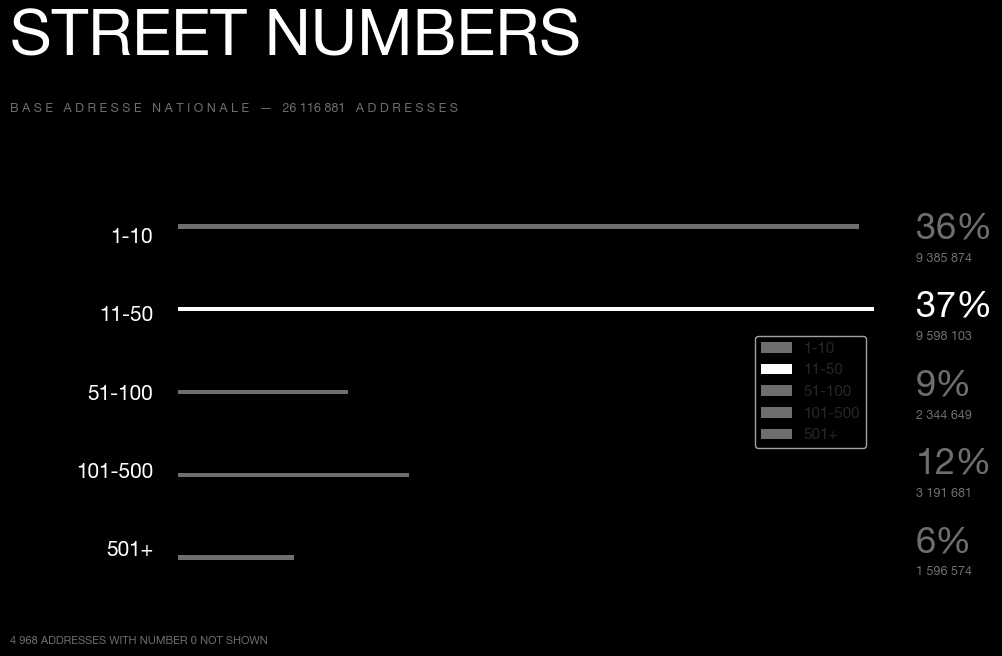

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import font_manager

hist = result.collect()
order  = ["1-10", "11-50", "51-100", "101-500", "501+"]
counts = dict(hist)
values = [counts.get(b, 0) for b in order]
total  = sum(values)
shares = [v / total for v in values]

available = {f.name for f in font_manager.fontManager.ttflist}
FONT = next(f for f in ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"] if f in available)
BLACK, WHITE, GREY = "#000000", "#FFFFFF", "#6E6E6E"

sns.set_theme(style="white", rc={
    "font.family": FONT,
    "figure.facecolor": BLACK,
    "axes.facecolor": BLACK,
})

fig, ax = plt.subplots(figsize=(12, 7))
fig.subplots_adjust(left=0.20, right=0.78, top=0.68, bottom=0.12)

top = max(values)
colors = [WHITE if v == top else GREY for v in values]
sns.barplot(x=values, y=order, hue=order, palette=colors,
            orient="h", width=0.28, linewidth=0, ax=ax)

for i, (v, s) in enumerate(zip(values, shares)):
    c = WHITE if v == top else GREY
    ax.text(top * 1.06, i - 0.08, f"{s:.0%}", va="center", ha="left",
            fontsize=26, fontweight="black", color=c)
    ax.text(top * 1.06, i + 0.30, f"{v:,}".replace(",", " "), va="center", ha="left",
            fontsize=9, color=GREY)

ax.set_xlim(0, top)
ax.set_xticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="y", length=0, pad=18)
for lab in ax.get_yticklabels():
    lab.set_color(WHITE)
    lab.set_fontsize(15)
    lab.set_fontweight("bold")
sns.despine(left=True, bottom=True)

fig.text(0.06, 0.88, "STREET NUMBERS", fontsize=46, fontweight="black", color=WHITE)
fig.text(0.06, 0.80,
         "B A S E   A D R E S S E   N A T I O N A L E   —   "
         + f"{total:,}".replace(",", " ") + "   A D D R E S S E S",
         fontsize=9, color=GREY)
fig.text(0.06, 0.04, "4 968 ADDRESSES WITH NUMBER 0 NOT SHOWN", fontsize=8, color=GREY)

plt.show()

---
## Exercise 9: Municipalities Sharing the Same Street Name
**Goal:** Find street names that exist in more than 50 distinct municipalities.

**Allowed RDD Functions:** `.map()`, `.distinct()`, `.reduceByKey()`, `.filter()`

In [32]:
print("Exercise 9")
# TODO: Write your MapReduce code here
result = (
    adresses_rdd.filter(lambda x : x[4] != "")
                .map(lambda x: (x[4],x[6])).distinct()
                .map(lambda x: (x[0],1))
                .reduceByKey(lambda x,y: x+y).filter(lambda x : x[1] > 50)
                .take(5)

)

Exercise 9


26/10/25 21:33:16 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 21:33:16 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 21:33:16 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


In [33]:
result

[('Rue du Repos', 155),
 ('Avenue de la Gare', 989),
 ('Rue des Châtaigniers', 297),
 ('Rue des Ecoles', 2456),
 ('Impasse des Charmes', 161)]

---
## Exercise 10: Department Address Density Rank
**Goal:** Count unique municipalities per department and calculate the ratio: `total_addresses / total_municipalities`. Display top 5 departments by this ratio.

**Allowed RDD Functions:** `.map()`, `.reduceByKey()`, `.join()` / `.aggregateByKey()`

### Using the full postal code makes the denominator almost always 1 (most postal codes map to a single municipality), so the ratio degenerates into a plain address count. I use the first two digits as a department proxy here.

In [36]:
print("Exercise 10")
# TODO: Write your MapReduce code here

share_base = (
    adresses_rdd.filter(lambda x :x[5] != "")
                .map(lambda x: (x[5][:2],x[6]))
)
count_address = (
    share_base.map(lambda x: (x[0],1))
              .reduceByKey(lambda x, y: x+y)
)
count_muni = (
    share_base.distinct()
              .map(lambda x : (x[0],1))
              .reduceByKey(lambda x, y:x+y)
)

result = (
    count_address.join(count_muni)
                 .map(lambda x: (x[0],x[1][0]/x[1][1]))
                 .takeOrdered(5,key = lambda x: -x[1])
)

result

Exercise 10


26/10/25 21:55:20 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/25 21:55:20 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 21:55:20 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory
26/10/25 21:55:22 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 23.3 MiB so far)
26/10/25 21:55:22 WARN BlockManager: Putting block rdd_3_0 failed
26/10/25 21:55:22 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[('75', 7631.4),
 ('98', 6495.666666666667),
 ('93', 6032.025641025641),
 ('97', 5859.295454545455),
 ('92', 4618.5)]

---
## Exercise 11: Distance to Paris Zero Point
**Goal:** Compute the Haversine distance (in km) from each address to Notre-Dame Paris (48.8534 N, 2.3488 E). Find the furthest single address in mainland France (departments starting with 0-9, excluding DOM-TOM > 97).

**Allowed RDD Functions:** `.map()`, `.filter()`, `.reduce()` / `.top()`

### i was using the first 2 letters of code postal to determine whether the address is reunion or some other overseas territory, don't know the haversine distance so I ask llm for help for this function

In [39]:
print("Exercise 11")
# TODO: Write your MapReduce code here
import math

def haversine(lat1, lon1, lat2, lon2, R=6371.0):
    
    
    phi1 = math.radians(lat1)
    phi2 = math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlmb = math.radians(lon2 - lon1)

    
    a = math.sin(dphi / 2) ** 2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlmb / 2) ** 2
    c = 2 * math.asin(math.sqrt(a))

    
    return R * c

result = (
    adresses_rdd.filter(lambda x : x[5] != '' and int(x[5][:2]) < 97 )
                .map(lambda x: (haversine(lat1 = float(x[13]),lon1 = float(x[12]),lat2 = 48.8534,lon2 = 2.3488),x[4],x[5],x[7]))
                .top(10)
)

result

Exercise 11


26/10/26 14:24:34 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 14:24:34 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 14:24:34 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[(993.235418422022, 'Ile Cavallo', '20169', 'Bonifacio'),
 (993.140401690742, 'Ile Cavallo', '20169', 'Bonifacio'),
 (992.6509432391357, 'Ile Cavallo', '20169', 'Bonifacio'),
 (992.6406487919548, 'Ile Cavallo', '20169', 'Bonifacio'),
 (992.636500861933, 'Ile Cavallo', '20169', 'Bonifacio'),
 (992.3718083449396, 'Ile Cavallo', '20169', 'Bonifacio'),
 (992.2379735442755, 'Ile Cavallo', '20169', 'Bonifacio'),
 (992.234709730841, 'Ile Cavallo', '20169', 'Bonifacio'),
 (990.4410954964212, 'Sperone', '20169', 'Bonifacio'),
 (990.4223689480401, 'Sperone', '20169', 'Bonifacio')]

---
## Exercise 12: Identify Outlier Addresses
**Goal:** Find addresses whose coordinates fall outside valid French mainland/overseas boundaries (`lat < -90` or `lat > 90` or `lon < -180` or `lon > 180` or `lat == 0.0` or `lon == 0.0`). Count total outliers.

**Allowed RDD Functions:** `.filter()`, `.count()`

In [40]:
print("Exercise 12")
# TODO: Write your MapReduce code here

result = (
    adresses_rdd.filter(lambda x: float(x[13])<-90 or float(x[13]) >90 or float(x[13]) == 0.0 or float(x[12])<-180 or float(x[12])>180 or float(x[12]) == 0.0 )
                .count()
)
result


Exercise 12


26/10/26 14:34:26 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 14:34:26 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 14:34:26 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


0

---
## Exercise 13: Top Street Name per Department
**Goal:** Find the single most frequent street name for EACH department.

**Allowed RDD Functions:** `.map()`, `.reduceByKey()`, `.groupByKey()` / `.reduceByKey()`

In [46]:
print("Exercise 13")
# TODO: Write your MapReduce code here

result = (
    adresses_rdd.map(lambda x: ((x[5][:2],x[4]),1))
                .reduceByKey(lambda x,y:x+y)
                .map(lambda x: (x[0][0],(x[0][1],x[1])))
                .reduceByKey(lambda x,y: x if x[1] > y[1] else y)
)

result.collect()

Exercise 13


26/10/26 14:54:53 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 14:54:53 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 14:54:53 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[('01', ('Grande Rue', 4407)),
 ('02', ('Grande Rue', 3938)),
 ('03', ('Grande Rue', 1082)),
 ('42', ('Rue de la République', 1225)),
 ('04', ('Grand Rue', 923)),
 ('05', ('Route de Gap', 583)),
 ('06', ('Route de Nice', 806)),
 ('07', ('Grande Rue', 781)),
 ('08', ('Grande Rue', 2860)),
 ('09', ('Le Village', 701)),
 ('10', ('Grande Rue', 5748)),
 ('11', ('Le Village', 2650)),
 ('12', ('', 15224)),
 ('13', ('Avenue Jean Moulin', 885)),
 ('14', ("Rue de l'Église", 2285)),
 ('15', ('Rue de la Gare', 293)),
 ('16', ('Grand Rue', 769)),
 ('17', ('Grande Rue', 1656)),
 ('18', ('Grande Rue', 1492)),
 ('19', ('Le Bourg', 463)),
 ('21', ('Grande Rue', 6107)),
 ('22', ('Rue de la Gare', 1128)),
 ('23', ('Grande Rue', 981)),
 ('24', ('Rue de la République', 741)),
 ('33', ('Route de Bordeaux', 1955)),
 ('25', ('Grande Rue', 9699)),
 ('26', ('Grande Rue', 1716)),
 ('27', ('Grande Rue', 2268)),
 ('28', ('Grande Rue', 2746)),
 ('29', ('Rue de la Gare', 1205)),
 ('20', ('A Traversa', 606)),
 ('30',

### for 12 there're many null street name so if i could use the .filter rdd function i would filter out the null values first

---
## Exercise 14: Spatial Grid Indexing
**Goal:** Partition coordinates into a spatial grid of size 0.1 x 0.1 degrees. Find the top 3 grid cells containing the highest density of addresses.
Grid cell key format: `(floor(lat / 0.1), floor(lon / 0.1))`

**Allowed RDD Functions:** `.map()`, `.reduceByKey()`, `.takeOrdered()`

In [49]:
print("Exercise 14")
# TODO: Write your MapReduce code here
result = (
    adresses_rdd.map(lambda x : ((math.floor(float(x[13])),math.floor(float(x[12]))),1) )
                .reduceByKey(lambda x, y : x +y)
                .takeOrdered(3,key = lambda x : -x[1])
)
result

Exercise 14


26/10/26 15:25:15 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 15:25:15 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 15:25:15 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[((48, 2), 1761042), ((50, 3), 779070), ((45, 4), 708548)]

---
## Exercise 15: Find Homonym Communes
**Goal:** Identify municipality names (`nom_commune`) that correspond to multiple INSEE codes. List the top 5 commune names with the highest number of distinct INSEE codes.

**Allowed RDD Functions:** `.map()`, `.distinct()`, `.reduceByKey()`, `.filter()`, `.sortBy()`

In [51]:
print("Exercise 15")
# TODO: Write your MapReduce code here

result =(
    adresses_rdd.map(lambda x : (x[7],x[6])).distinct()
                .map(lambda x : (x[0],1))
                .reduceByKey(lambda x,y:x+y)
                .filter(lambda x :x[1] > 1)
                .sortBy(lambda x : x[1], ascending = False).take(5)
)
result


Exercise 15


26/10/26 15:48:35 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 15:48:35 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 15:48:35 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[('Sainte-Colombe', 12),
 ('Saint-Sauveur', 11),
 ('Saint-Aubin', 10),
 ('Beaulieu', 10),
 ('Saint-Marcel', 9)]

---
## Exercise 16: Jaccard Similarity of Street Names Between Two Departments
**Goal:** Compute the Jaccard Similarity index (size of intersection / size of union) between the set of unique street names in department `'75'` (Paris) and department `'92'` (Hauts-de-Seine).

**Allowed RDD Functions:** `.filter()`, `.map()`, `.distinct()`, RDD set operations (`.intersection()`, `.union()`) or MapReduce equivalent.

In [52]:
print("Exercise 16")
# TODO: Write your MapReduce code here
paris = (
    adresses_rdd.filter(lambda x : x[5][:2] == "75" and x[4] != "")
                .map(lambda x : x[4])
                .distinct()
)

haut_de_seine = (
    adresses_rdd.filter(lambda x : x[5][:2] == "92" and x[4] != "")
                .map(lambda x : x[4])
                .distinct()
)

intersect = paris.intersection(haut_de_seine).count()
union = paris.union(haut_de_seine).distinct().count()

jaccard = intersect / union

print(jaccard)

Exercise 16


26/10/26 16:19:17 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 16:19:17 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 16:19:17 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory
26/10/26 16:19:19 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 23.3 MiB so far)
26/10/26 16:19:19 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 16:19:19 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


0.042697594501718214


---
## Exercise 17: Standard Deviation & Percentile Histogram Estimation
**Goal:** Compute the exact Standard Deviation and estimated 25th, 50th (Median), and 75th percentiles of street numbers nationally in a memory-efficient MapReduce pass.

**Allowed RDD Functions:** `.flatMap()`, `.aggregateByKey()` / `.reduceByKey()`, `.sortByKey()`

In [53]:
print("Exercise 17")
# TODO: Write your MapReduce code here
std_rdd = (
    adresses_rdd.flatMap(lambda x : [("dummykey",int(x[2]))])
                .aggregateByKey(
                    (0,0,0),
                    lambda x,y : (x[0] + 1, x[1] + y, x[2] + y*y),
                    lambda x,y : (x[0] + y[0],x[1] + y[1],x[2] + y[2])

                )
)
result = std_rdd.collect()
n,s,q = result[0][1]

mean = s/n
var = q/n - mean**2
std = math.sqrt(var)

print(n,mean,std)

Exercise 17


26/10/26 17:34:33 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 17:34:33 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 17:34:33 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


26121849 127.88273732077695 3485.405626364127


In [55]:
hist = (
    adresses_rdd.flatMap(lambda x : [(int(x[2]),1)])
                .reduceByKey(lambda x,y : x + y)
                .sortByKey()
                .collect()
)

def percentile(hist_sorted, p, n):
    target = p * n
    cum = 0
    for value, count in hist_sorted:
        cum += count
        if cum >= target:
            return value

p25 = percentile(hist, 0.25, n)
p50 = percentile(hist, 0.50, n)
p75 = percentile(hist, 0.75, n)
print(p25, p50, p75)

26/10/26 17:40:01 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 17:40:01 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 17:40:01 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


7 18 59


### for the threshold of max I only set to 200 as there's outlier

/Users/apple/anaconda3/lib/python3.11/site-packages/seaborn/_oldcore.py:1765: FutureWarning: unique with argument that is not not a Series, Index, ExtensionArray, or np.ndarray is deprecated and will raise in a future version.
  order = pd.unique(vector)


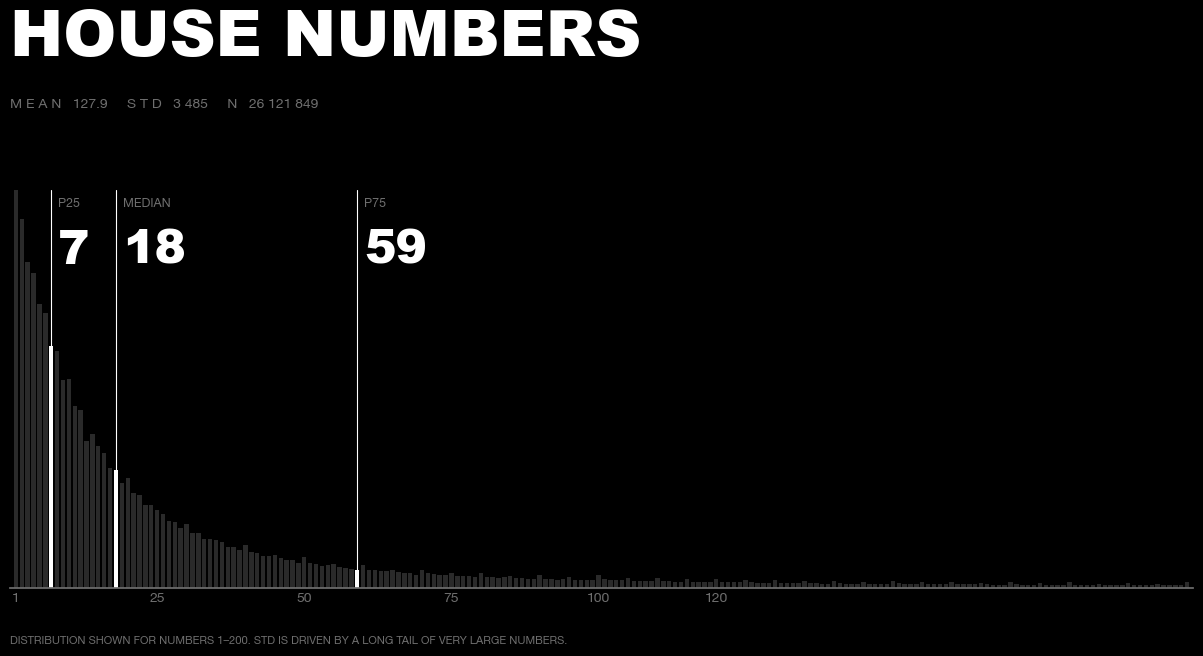

In [64]:
MAX_X = 200
xs = [v for v, c in hist if 1 <= v <= MAX_X]
ys = [c for v, c in hist if 1 <= v <= MAX_X]

available = {f.name for f in font_manager.fontManager.ttflist}
FONT  = next(f for f in ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"] if f in available)
TITLE = next((f for f in ["Arial Black", "Helvetica Neue", "Arial"] if f in available), FONT)
BLACK, WHITE, GREY, DARK = "#000000", "#FFFFFF", "#6E6E6E", "#2A2A2A"
sp = lambda v: f"{v:,.0f}".replace(",", " ")

sns.set_theme(style="white", rc={"font.family": FONT,
                                 "figure.facecolor": BLACK, "axes.facecolor": BLACK})
fig, ax = plt.subplots(figsize=(13, 7))
fig.subplots_adjust(left=0.06, right=0.97, top=0.70, bottom=0.12)

sns.barplot(x=xs, y=ys, color=DARK, width=0.75, linewidth=0, ax=ax)
if ax.get_legend() is not None:          
    ax.get_legend().remove()

pos = {v: p.get_x() + p.get_width() / 2 for v, p in zip(xs, ax.patches)}

marks = {p25: "P25", p50: "MEDIAN", p75: "P75"}
top = max(ys)
for v, label in marks.items():
    i = xs.index(v)
    ax.patches[i].set_facecolor(WHITE)
    x = pos[v]
    ax.plot([x, x], [ys[i], top], color=WHITE, linewidth=0.8)
    ax.text(x + 1.2, top * 0.98, label, color=GREY, fontsize=9, va="top")
    ax.text(x + 1.2, top * 0.90, str(v), color=WHITE, fontsize=34,
            fontweight="bold", fontfamily=TITLE, va="top")


ticks = [1, 25, 50, 75, 100, 120]
ax.set_xticks([pos[t] for t in ticks])
ax.set_xticklabels([str(t) for t in ticks])
ax.set_xlim(pos[xs[0]] - 1, pos[xs[-1]] + 1)
ax.set_ylim(0, top * 1.02)
ax.set_yticks([])
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", length=0, colors=GREY, labelsize=10)
sns.despine(left=True)
ax.spines["bottom"].set_color(GREY)


fig.text(0.06, 0.88, "HOUSE NUMBERS", fontsize=46, fontweight="bold", fontfamily=TITLE, color=WHITE)
fig.text(0.06, 0.805,
         "M E A N   " + f"{mean:.1f}" + "     S T D   " + sp(std) + "     N   " + sp(n),
         fontsize=10, color=GREY)
fig.text(0.06, 0.04, f"DISTRIBUTION SHOWN FOR NUMBERS 1–{MAX_X}. "
         "STD IS DRIVEN BY A LONG TAIL OF VERY LARGE NUMBERS.", fontsize=8, color=GREY)

plt.show()

---
## Exercise 18: Spatial Self-Join / Nearest Address Pair
**Goal:** Partition addresses in postal code `'75001'` into 0.005x0.005 degree spatial buckets. For each bucket, find the single pair of distinct addresses that are closest to each other in meters. Output the minimum-distance pair and the distance between them in metres per bucket.

**Note:**
- 1 degree of latitude is approximately $111.1$ km.
- 1 degree of longitude is approximately $111.1 \times \cos(\text{latitude})$ km.

**Allowed RDD Functions:** `.filter()`, `.map()`, `.reduce()`, `.aggregateByKey()`, `.sortBy()`, `.flatMap()`

In [69]:
print("Exercise 18")
# TODO: Write your MapReduce code here
import itertools
def dist_m(lat1, lon1, lat2, lon2):
    
    dy = (lat2 - lat1) * 111100
    dx = (lon2 - lon1) * 111100 * math.cos(math.radians((lat1 + lat2) / 2))
    return math.sqrt(dx ** 2 + dy ** 2)

def closest_pair(kv):
    bucket, addrs = kv                       
    if len(addrs) < 2:
        return []

    best = None
    for a, b in itertools.combinations(addrs, 2):
        d = dist_m(a[2], a[3], b[2], b[3])
        if best is None or d < best[0]:
            best = (d, a[1], b[1])

    return [ ( bucket , best ) ]

result = (
    adresses_rdd.filter(lambda x : x[5] == "75001")
                .map(lambda x : (
                    (math.floor(float(x[13]) / 0.005),math.floor(float(x[12]) / 0.005)),(x[0],x[4],float(x[13]), float(x[12]))
                ))
                .aggregateByKey(
                    [],
                    lambda x, y: x + [y],
                    lambda x, y : x + y
                )
                .flatMap(lambda x : closest_pair(x))
                .sortBy(lambda x: x[1][0])
                .collect()
)

result

Exercise 18


26/10/26 20:26:52 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 20:26:52 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 20:26:52 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[((9772, 469),
  (0.3127579539120999, 'Place de la Rotonde', 'Place de la Rotonde')),
 ((9772, 467),
  (0.9892029472032828, 'Galerie de Montpensier', 'Passage de Montpensier')),
 ((9773, 467),
  (2.2982576359744056, 'Galerie de Beaujolais', 'Galerie de Beaujolais')),
 ((9772, 468),
  (2.298468188891218, 'Impasse des Bourdonnais', 'Impasse des Bourdonnais')),
 ((9771, 469), (2.704004910666675, 'Rue des Lombards', 'Rue des Lombards')),
 ((9773, 466), (2.758592809021794, "Rue d'Argenteuil", 'Rue Saint-Roch')),
 ((9772, 466), (3.546905971644972, 'Rue Saint-Honoré', 'Rue Saint-Honoré')),
 ((9771, 468), (3.8034496376731206, 'Rue de Harlay', 'Place Dauphine')),
 ((9773, 464), (5.096435750054198, 'Rue Saint-Honoré', 'Rue Saint-Honoré')),
 ((9773, 465), (5.8606949051579456, 'Rue Saint-Honoré', 'Rue Saint-Honoré')),
 ((9770, 468), (5.9438646119450045, 'Quai des Orfèvres', 'Quai des Orfèvres')),
 ((9773, 468), (6.65890925788118, 'Rue Herold', 'Rue Herold')),
 ((9772, 470),
  (8.049143538778685, '

---
## Exercise 19: Street Name Bigram Analysis
**Goal:** Tokenize all street names into 2-grams (bigrams of consecutive words). Find the top 10 most frequent street name bigrams in France.

**Allowed RDD Functions:** `.flatMap()`, `.reduceByKey()`, `.takeOrdered()`

In [71]:
print("Exercise 19")
# TODO: Write your MapReduce code here
def bigrams(x):
    words = x[4].split()
    return [ ( (a, b), 1 ) for a, b in zip(words, words[1:]) ]

result = (
    adresses_rdd.flatMap(lambda x : bigrams(x))
                .reduceByKey(lambda x, y : x + y)
                .takeOrdered(10, key = lambda x :-x[1])
)

result

Exercise 19


26/10/26 20:47:58 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 20:47:58 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 20:47:58 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[(('Rue', 'de'), 3345123),
 (('de', 'la'), 3097131),
 (('Rue', 'du'), 2377079),
 (('Rue', 'des'), 2131390),
 (('Route', 'de'), 1595921),
 (('Chemin', 'de'), 992097),
 (('Chemin', 'des'), 502766),
 (('Chemin', 'du'), 458961),
 (('Avenue', 'de'), 416319),
 (('Impasse', 'des'), 374064)]

---
## Exercise 20: Prefix Trie Frequency Analysis
**Goal:** For each letter `'A'` through `'Z'`, find the 3 most common 3-character prefixes of street names starting with that letter.

**Allowed RDD Functions:** `.flatMap()`, `.reduceByKey()`, `.groupByKey()`, `.mapValues()`

In [72]:
print("Exercise 20")
# TODO: Write your MapReduce code here

def prefix_pair(row):
    name = row[4].upper()
    if len(name) < 3:
        return []                   
    return [ (name[:3], 1 ) ]

result = (
    adresses_rdd.flatMap(lambda x : prefix_pair(x))
                .reduceByKey(lambda x, y : x + y)
                .flatMap(lambda x : [(x[0][:1],(x))])
                .groupByKey()
                .mapValues(lambda x : sorted(x,key = lambda y:-y[1])[:3])
)

result.collect()
           

Exercise 20


26/10/26 21:51:38 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 21:51:38 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 21:51:38 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


[('C', [('CHE', 2308627), ('CIT', 74466), ('COU', 62584)]),
 ('A', [('AVE', 1544235), ('ALL', 931221), ('ANC', 13515)]),
 ('R', [('RUE', 13380774), ('ROU', 2601511), ('RÉS', 104594)]),
 ('P', [('PLA', 485330), ('PAS', 53021), ('PET', 16417)]),
 ('B', [('BOU', 380557), ('BEL', 8148), ('BOI', 5232)]),
 ('I', [('IMP', 1327982), ('ILO', 1408), ('IMM', 1308)]),
 ('M', [('MON', 56354), ('MOU', 8292), ('MAI', 8125)]),
 ('L', [('LA ', 346078), ('LE ', 253355), ('LOT', 219927)]),
 ('S', [('SQU', 65564), ('STR', 42165), ('SEN', 33594)]),
 ('D', [('DOM', 25897), ('DES', 2713), ('DRA', 1160)]),
 ('Z', [('ZON', 13150), ('ZA ', 3787), ('ZAC', 1278)]),
 ('E', [('ESP', 7387), ('ESC', 2186), ('ENC', 1722)]),
 ('H', [('HAM', 68558), ('HEN', 16837), ('HAU', 2941)]),
 ('G', [('GRA', 241920), ('GUE', 2630), ('GAR', 1876)]),
 ('V', [('VOI', 42238), ('VIL', 37154), ('VEN', 10728)]),
 ('F', [('FAU', 18518), ('FER', 5997), ('FON', 2959)]),
 ('T', [('TRA', 32056), ('TRE', 4449), ('TOU', 3614)]),
 ('Q', [('QUA',

---
## Exercise 21: Department with Maximum Homonym Communes
**Goal:** Identify the department that contains the highest count of homonym communes using two different map-reduce approaches:
- Using some intermediate result obtained from Exercise 15
- Any other approach

Identify the map and reduce stages for both solutions, and show which approach is more efficient with empirical justifications.

**Allowed RDD Functions:** `.map()`, `.distinct()`, `.reduceByKey()`, `.filter()`, `.sortBy()`

In [78]:
print("Exercise 21")
# TODO: Write your MapReduce code here
import time

t0 = time.perf_counter()

result_1 = (
    adresses_rdd.map(lambda x : (x[7],x[6])).distinct()
                .map(lambda x : (x[0],1)).reduceByKey(lambda x, y: x + y)
                .filter(lambda x : x[1] >1)
                .map(lambda x : x[0]).collect()
)

homonym_names = set(result_1)
bc = sc.broadcast(homonym_names)

top_1 = (
    adresses_rdd.map(lambda x : (x[7],x[6])).distinct()
                .filter(lambda x: x[0] in bc.value)
                .map(lambda x :(x[1][:2],1)).reduceByKey(lambda x, y: x +y)
                .sortBy(lambda x: x[1],ascending = False)
)
top_1.take(5)

t_v2 = time.perf_counter() - t0
print("Approach 1:", top_1, f"{t_v2:.1f}s")

Exercise 21


26/10/26 22:23:46 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 22:23:46 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 22:23:46 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory
26/10/26 22:25:40 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 22:25:40 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 22:25:40 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


Approach 1: PythonRDD[361] at RDD at PythonRDD.scala:59 227.3s


In [79]:

name_insee = adresses_rdd.map(lambda x: (x[7], x[6])).distinct().cache()   
name_insee.count()                                                         

t0 = time.perf_counter()
names_v2 = set(name_insee.map(lambda x: (x[0], 1)).reduceByKey(lambda a, b: a + b)
                         .filter(lambda x: x[1] > 1).map(lambda x: x[0]).collect())
bc1 = sc.broadcast(names_v2)
top_v1 = (name_insee.filter(lambda x: x[0] in bc1.value)
                    .map(lambda x: (x[1][:2], 1))
                    .reduceByKey(lambda a, b: a + b)
                    .sortBy(lambda x: x[1], ascending=False)
                    .take(5))
t_v2 = time.perf_counter() - t0
print("Approach 2:", top_v1, f"{t_v2:.1f}s")

26/10/26 22:28:42 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/26 22:28:42 WARN BlockManager: Putting block rdd_3_0 failed
26/10/26 22:28:42 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


Approach 2: [('02', 93), ('33', 90), ('71', 85), ('60', 83), ('21', 81)] 0.2s


### Exercise 21 — What I learned

**Answer:** Aisne (department 02) has the most homonym communes, with 93. The department is taken from the first two characters of the INSEE code, so Corsica appears as 2A/2B and the overseas departments are grouped under 97.

### How I used an LLM

I asked an LLM two things: how to reuse my work from Exercise 15, and why one approach could be much faster than the other. It suggested rewriting Exercise 15 so that each intermediate RDD is stored in its own variable instead of being chained and thrown away. It also explained `cache()` and `broadcast`. I wrote and ran the final code myself and measured the times on my laptop.

### The two approaches in plain words

Both approaches do the same two steps:
1. Find the commune names that are used by more than one commune (more than one INSEE code).
2. Keep only those communes and count them per department.

The only difference is where they start.

- **Approach 1** starts from `name_insee`, the list of 34,896 distinct (name, INSEE) pairs I had already built in Exercise 15 and kept in memory with `cache()`.
- **Approach 2** starts again from the raw data (26 million addresses) and rebuilds the (name, INSEE) pairs from scratch. It does this twice, once for each step.

### Why one is fast and the other is slow

The most important thing I learned is that **Spark is lazy**. An RDD is not stored data; it is a recipe. Every time I ask for a result (`take`, `count`, …), Spark follows the recipe again from the original file, unless I have told it to keep the result with `cache()`.

On my laptop, reading and parsing the 26 million rows once takes about 113 seconds. So:

- **Approach 2** reads the raw file twice: **227.3 s**, almost exactly 2 × 113 s.
- **Approach 1** starts from 35,000 rows that are already in memory: **0.2 s**.

Even if I count the 113 s needed once to build the cache, Approach 1 is still about twice as fast, and the advantage grows every time `name_insee` is reused.

A second reason is `distinct()`. To remove duplicates, Spark has to bring identical rows from different partitions together (a shuffle), which is expensive on millions of rows. Approach 2 does this twice on the full data; Approach 1 has already paid this cost once.

### Filtering with a small list: broadcast

The list of homonym names is small (1,440 names). We cannot use `join`, so I collected the names into a Python `set` and sent one copy to every worker with `sc.broadcast()`. Each worker can then check `name in set` locally, without moving data between partitions. I learned that this is called a broadcast join, and that it is a standard trick when one side is small.

### Map and reduce stages

- **Approach 1** — Map: `map → (name, 1)`, then `filter` + `map → (department, 1)`. Reduce: `reduceByKey` per name, then `reduceByKey` per department.
- **Approach 2** — Map: `map → (name, INSEE)` twice, `map → (name, 1)`, `filter` + `map → (department, 1)`. Reduce: `distinct` twice, `reduceByKey` per name, `reduceByKey` per department.

### Takeaway

The speed of a Spark job depends mostly on **how many times it reads the big raw data**, not on how short the code looks. If an intermediate result is small and used more than once, it should be cached and reused.

---
## Exercise 22: Identify the Most Prominent Geographical Area
**Goal:** Identify the geographical area using bounding boxes of area 100 square kilometers containing the maximum number of addresses. How many postal codes does this geographical area share? You need to use two different map-reduce approaches:
- Without using `.reduce()`
- Without using `.reduceByKey()`

Identify the map and reduce stages for both solutions, and show which approach is more efficient with empirical justifications.

**Note:**
- 1 degree of latitude is approximately $111.1$ km.
- 1 degree of longitude is approximately $111.1 \times \cos(\text{latitude})$ km.

In [80]:
print("Exercise 22")
# TODO: Write your MapReduce code here

import math
import time
DLAT = 10 / 111.1

def cell_100km2(lat, lon):
    i = math.floor(lat / DLAT)
    lat_c = (i + 0.5) * DLAT
    dlon = 10 / (111.1 * math.cos(math.radians(lat_c)))
    j = math.floor(lon / dlon)
    return (i, j)

t0 = time.perf_counter()
cell_counts = (
    adresses_rdd.map(lambda x: (cell_100km2(float(x[13]), float(x[12])), 1))
                .reduceByKey(lambda x, y: x + y)
)
best_cell, best_n = cell_counts.top(1, key=lambda x: x[1])[0]
n_postal_A = (
    adresses_rdd.filter(lambda x: cell_100km2(float(x[13]), float(x[12])) == best_cell)
                .map(lambda x: x[5])
                .distinct()
                .count()
)
t_A = time.perf_counter() - t0
print("Approach A:", best_cell, best_n, n_postal_A, f"{t_A:.1f}s")

t0 = time.perf_counter()


best = (
    adresses_rdd.map(lambda x: (cell_100km2(float(x[13]), float(x[12])), x[5]))
                .aggregateByKey(
                    (0, set()),
                    lambda x, y: (x[0] + 1, x[1] | {y}),
                    lambda x, y: (x[0] + y[0], x[1] | y[1])
                )
                .reduce(lambda x, y: x if x[1][0] >= y[1][0] else y)
)
best_cell_B, (best_n_B, postal_set) = best
n_postal_B = len(postal_set)
t_B = time.perf_counter() - t0
print("Approach B:", best_cell_B, best_n_B, n_postal_B, f"{t_B:.1f}s")
sc.stop()


Exercise 22


26/10/27 11:57:07 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/27 11:57:07 WARN BlockManager: Putting block rdd_3_0 failed
26/10/27 11:57:07 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory
26/10/27 11:59:04 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/27 11:59:04 WARN BlockManager: Putting block rdd_3_0 failed
26/10/27 11:59:04 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


Approach A: (542, 17) 140120 40 238.4s


26/10/27 12:01:04 WARN MemoryStore: Not enough space to cache rdd_3_0 in memory! (computed 406.1 MiB so far)
26/10/27 12:01:04 WARN BlockManager: Putting block rdd_3_0 failed
26/10/27 12:01:04 WARN BlockManager: Block rdd_3_0 could not be removed as it was not found on disk or in memory


Approach B: (542, 17) 140120 40 117.3s


### Exercise 22 — What I learned

**Answer:** The densest 100 km² area is cell (542, 17), in central Paris (it contains Notre-Dame). It holds 140,120 addresses and shares 40 different postal codes.

### How I used an LLM

I asked an LLM how to turn latitude and longitude (in degrees) into 10 km × 10 km boxes, and how to answer "how many addresses?" and "how many postal codes?" at the same time without `reduceByKey`. I wrote and ran the code myself and measured the times.

### Building the grid

A box of 100 km² is 10 km × 10 km. One degree of latitude is always about 111.1 km, so the north–south step is always 10 / 111.1 ≈ 0.09°.

What I did not know before: **one degree of longitude gets shorter as you move away from the equator**. It is about 111.1 × cos(latitude) km. So the east–west step has to change with latitude: 10 / (111.1 × cos(latitude)). I used the centre latitude of each horizontal band, so that every box is close to 100 km², whether it is in the south or the north of France.

### The two approaches in plain words

- **Approach A (without `reduce`)** — First I count the addresses in each box with `reduceByKey` and pick the winning box with `top(1)`. But a count does not tell me which postal codes are inside. So I have to **read the 26 million rows a second time**, keep only the addresses in the winning box, take their postal codes, remove duplicates with `distinct`, and count them.
- **Approach B (without `reduceByKey`)** — I use `aggregateByKey`, which lets me keep a small "notebook" for each box: **(number of addresses, set of postal codes)**. For each address, I add 1 to the count and put its postal code into the set. A set ignores duplicates automatically, so its size is the number of distinct postal codes. Then `reduce` keeps the box with the highest count. **One single pass answers both questions.**

### Why one is fast and the other is slow

As in Exercise 21, the expensive part is reading and parsing the 26 million raw rows (about 113 s each time on my laptop).

- **Approach A** reads the raw data **twice**: **__ s**
- **Approach B** reads it **once**: **__ s**

The lesson I took from this: when two questions are about the same groups, it is better to design the accumulator so that it carries **everything needed in one pass**, instead of answering one question and then going back to the data for the second.

I also learned that this has a cost: Approach B keeps a set for every box, so it uses more memory per key. Here it is fine, because there are about 6,000 boxes and each set holds only a few dozen postal codes. With millions of keys or very large sets, this design could become a problem.

### Map and reduce stages

- **Approach A** — Map: `map → (box, 1)`; second pass: `filter` (winning box) + `map → postal code`. Reduce: `reduceByKey` (count per box), `top(1)` (winner), `distinct` + `count` (postal codes).
- **Approach B** — Map: `map → (box, postal code)`. Reduce: `aggregateByKey` with a `(count, set of postal codes)` accumulator, then `reduce` (winner).

### Takeaway

Exercises 21 and 22 taught me the same rule in two ways: **the number of full scans over the raw data drives the running time.** Reusing results (cache) and computing several answers in one pass are the two main ways to reduce it.